# Learning-Rate Schedules

A learning-rate scheduler changes the step size during training: typically larger early on for fast progress, smaller later so stochastic gradients settle near a minimum. In `braintools.optim` a scheduler is an object you pass as `lr`:

```python
sched = braintools.optim.CosineAnnealingLR(base_lr=0.1, T_max=100)
opt = braintools.optim.SGD(lr=sched, momentum=0.9)
...
opt.update(grads)   # uses the scheduler's current learning rate
sched.step()        # advance the schedule (per epoch or per batch: your choice)
```

`step()` advances the schedule by one; `get_lr()` returns the current rate (one entry per parameter group). The schedule's position is stored in a `brainstate` state, so it is saved and restored with the optimizer. `ReduceLROnPlateau` is the exception: it is stepped with a metric, `sched.step(val_loss)`.

## 1. Setup

In [1]:
import brainstate
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools
from braintools import optim


def trace(sched, n):
    # learning rate after 0, 1, ..., n calls of step()
    lrs = [float(np.asarray(sched.get_lr()).ravel()[0])]
    for _ in range(n):
        sched.step()
        lrs.append(float(np.asarray(sched.get_lr()).ravel()[0]))
    return np.array(lrs)

## 2. The Schedules

Every built-in scheduler over 100 steps:

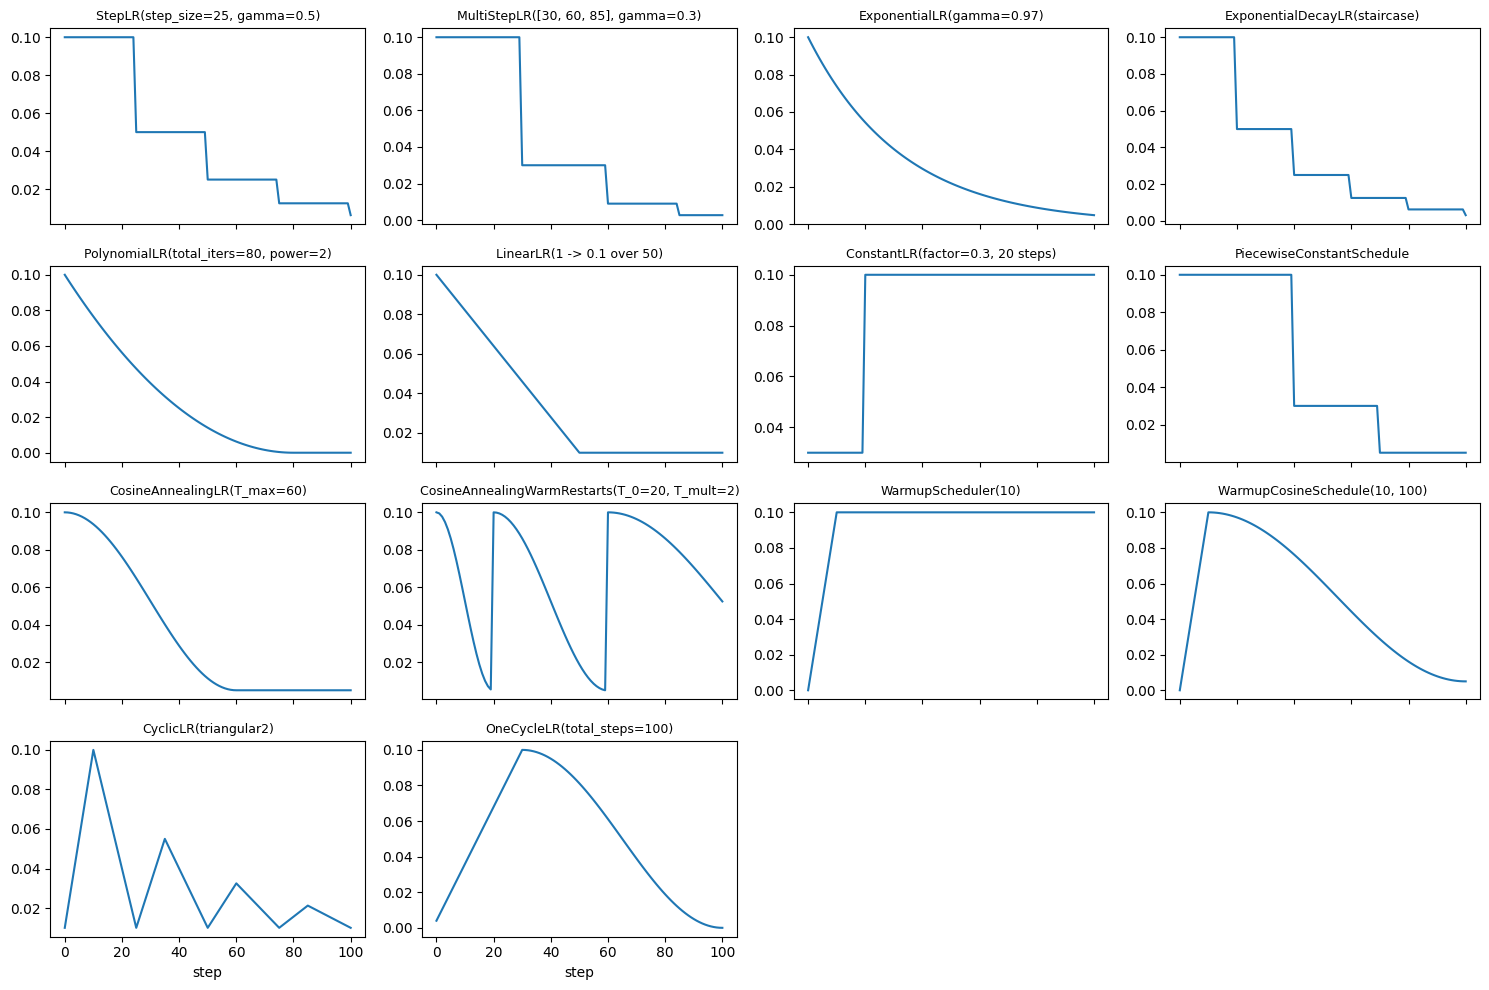

In [2]:
n = 100
schedules = {
    "StepLR(step_size=25, gamma=0.5)": optim.StepLR(0.1, step_size=25, gamma=0.5),
    "MultiStepLR([30, 60, 85], gamma=0.3)": optim.MultiStepLR(0.1, milestones=[30, 60, 85], gamma=0.3),
    "ExponentialLR(gamma=0.97)": optim.ExponentialLR(0.1, gamma=0.97),
    "ExponentialDecayLR(staircase)": optim.ExponentialDecayLR(0.1, decay_steps=20, decay_rate=0.5, staircase=True),
    "PolynomialLR(total_iters=80, power=2)": optim.PolynomialLR(0.1, total_iters=80, power=2.0),
    "LinearLR(1 -> 0.1 over 50)": optim.LinearLR(0.1, start_factor=1.0, end_factor=0.1, total_iters=50),
    "ConstantLR(factor=0.3, 20 steps)": optim.ConstantLR(0.1, factor=0.3, total_iters=20),
    "PiecewiseConstantSchedule": optim.PiecewiseConstantSchedule(boundaries=[40, 70], values=[0.1, 0.03, 0.005]),
    "CosineAnnealingLR(T_max=60)": optim.CosineAnnealingLR(0.1, T_max=60, eta_min=0.005),
    "CosineAnnealingWarmRestarts(T_0=20, T_mult=2)": optim.CosineAnnealingWarmRestarts(0.1, T_0=20, T_mult=2, eta_min=0.005),
    "WarmupScheduler(10)": optim.WarmupScheduler(0.1, warmup_epochs=10),
    "WarmupCosineSchedule(10, 100)": optim.WarmupCosineSchedule(0.1, warmup_steps=10, total_steps=100, eta_min=0.005),
    "CyclicLR(triangular2)": optim.CyclicLR(0.01, max_lr=0.1, step_size_up=10, step_size_down=15, mode="triangular2"),
    "OneCycleLR(total_steps=100)": optim.OneCycleLR(max_lr=0.1, total_steps=100),
}
fig, axes = plt.subplots(4, 4, figsize=(15, 10), sharex=True)
for ax, (name, sched) in zip(axes.flat, schedules.items()):
    ax.plot(trace(sched, n))
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(schedules):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("step")
fig.tight_layout()
plt.show()

A few behaviours worth knowing:

- Most schedules match `torch.optim.lr_scheduler` step for step (`StepLR`, `MultiStepLR`, `ExponentialLR`, `PolynomialLR`, `LinearLR`, `ConstantLR`, `CosineAnnealingWarmRestarts`, `CyclicLR`, `ReduceLROnPlateau`, `SequentialLR`; the next cell checks this when PyTorch is installed).
- `CosineAnnealingLR` **stays at `eta_min`** after `T_max`, whereas PyTorch's version follows the cosine back up. Use `CosineAnnealingWarmRestarts` for periodic schedules.
- `OneCycleLR` warms up **linearly** and anneals with `anneal_strategy` (cosine by default); PyTorch uses the annealing function for both phases.
- `PiecewiseConstantSchedule` takes **absolute** learning rates in `values`; `base_lr` is ignored.

In [3]:
try:
    import torch
except ImportError:
    torch = None

if torch is not None:
    T = torch.optim.lr_scheduler

    def torch_trace(make, base, n):
        p = torch.nn.Parameter(torch.zeros(1))
        o = torch.optim.SGD([p], lr=base)
        s = make(o)
        out = [o.param_groups[0]["lr"]]
        for _ in range(n):
            o.step()
            s.step()
            out.append(o.param_groups[0]["lr"])
        return np.array(out)

    pairs = {
        "StepLR": (optim.StepLR(0.1, step_size=25, gamma=0.5), lambda o: T.StepLR(o, 25, 0.5)),
        "CosineAnnealingWarmRestarts": (optim.CosineAnnealingWarmRestarts(0.1, T_0=20, T_mult=2, eta_min=0.005),
                                        lambda o: T.CosineAnnealingWarmRestarts(o, 20, 2, 0.005)),
        "CyclicLR(triangular2)": (optim.CyclicLR(0.01, max_lr=0.1, step_size_up=10, step_size_down=15, mode="triangular2"),
                                  lambda o: T.CyclicLR(o, 0.01, 0.1, 10, 15, mode="triangular2", cycle_momentum=False)),
        "CosineAnnealingLR (differs after T_max)": (optim.CosineAnnealingLR(0.1, T_max=60, eta_min=0.005),
                                                    lambda o: T.CosineAnnealingLR(o, 60, 0.005)),
    }
    for name, (ours, make) in pairs.items():
        base = float(np.asarray(ours.get_lr()).ravel()[0])
        diff = np.abs(trace(ours, n) - torch_trace(make, base, n))
        print(f"{name:42s} max |braintools - torch| = {diff.max():.1e}")

StepLR                                     max |braintools - torch| = 0.0e+00
CosineAnnealingWarmRestarts                max |braintools - torch| = 9.0e-09
CyclicLR(triangular2)                      max |braintools - torch| = 1.5e-08
CosineAnnealingLR (differs after T_max)    max |braintools - torch| = 7.1e-02


## 3. Composing Schedules

`SequentialLR(schedulers, milestones)` runs one scheduler after another: a linear warm-up for 10 steps, then cosine decay. `ChainedScheduler(schedulers)` steps all its schedulers together and **multiplies** their factors.

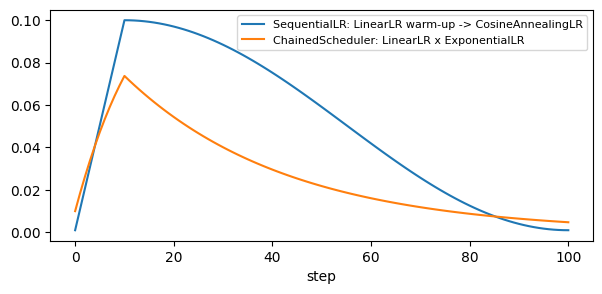

In [4]:
warmup = optim.LinearLR(0.1, start_factor=0.01, end_factor=1.0, total_iters=10)
cosine = optim.CosineAnnealingLR(0.1, T_max=90, eta_min=0.001)
sequential = optim.SequentialLR([warmup, cosine], milestones=[10])

chained = optim.ChainedScheduler([optim.LinearLR(0.1, start_factor=0.1, total_iters=10), optim.ExponentialLR(0.1, gamma=0.97)])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(trace(sequential, n), label="SequentialLR: LinearLR warm-up -> CosineAnnealingLR")
ax.plot(trace(chained, n), label="ChainedScheduler: LinearLR x ExponentialLR")
ax.set_xlabel("step")
ax.legend(fontsize=8)
plt.show()

## 4. Reacting to a Metric: `ReduceLROnPlateau`

`ReduceLROnPlateau` multiplies the rate by `factor` when the metric has not improved (by more than `threshold`) for `patience` steps. It is stepped with the metric:

In [5]:
sched = optim.ReduceLROnPlateau(0.1, mode="min", factor=0.5, patience=3)
val_losses = [1.0, 0.8, 0.7, 0.7, 0.7, 0.7, 0.7, 0.65, 0.65, 0.65, 0.65, 0.65, 0.65]
for epoch, loss in enumerate(val_losses):
    sched.step(loss)
    print(f"epoch {epoch:2d}: val loss {loss:.2f} -> lr {float(np.asarray(sched.get_lr()).ravel()[0]):.4f}")

epoch  0: val loss 1.00 -> lr 0.1000
epoch  1: val loss 0.80 -> lr 0.1000
epoch  2: val loss 0.70 -> lr 0.1000
epoch  3: val loss 0.70 -> lr 0.1000
epoch  4: val loss 0.70 -> lr 0.1000
epoch  5: val loss 0.70 -> lr 0.1000
epoch  6: val loss 0.70 -> lr 0.0500
epoch  7: val loss 0.65 -> lr 0.0500
epoch  8: val loss 0.65 -> lr 0.0500
epoch  9: val loss 0.65 -> lr 0.0500
epoch 10: val loss 0.65 -> lr 0.0500
epoch 11: val loss 0.65 -> lr 0.0250
epoch 12: val loss 0.65 -> lr 0.0250


## 5. Why Decay Helps: SGD on a Noisy Problem

With minibatch gradients, SGD at a constant learning rate does not converge: it keeps bouncing around the minimum in a noise ball whose size is proportional to the learning rate. Decaying the rate shrinks the ball. The problem below is least-squares regression with noisy targets; the plot shows the *excess* training loss above the exact least-squares optimum. All runs use SGD with momentum 0.9, a peak learning rate of 0.02, and minibatches of 8, and the schedulers are stepped once per batch.

constant 0.02                  excess loss after 20 epochs: 1.00e+00


StepLR (x0.2 every 5 epochs)   excess loss after 20 epochs: 1.82e-04


CosineAnnealingLR              excess loss after 20 epochs: 3.08e-04


OneCycleLR                     excess loss after 20 epochs: 1.16e-03


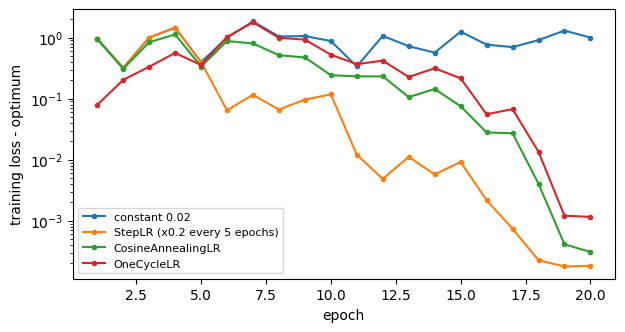

In [6]:
rng = np.random.default_rng(0)
n_samples, dim, batch, epochs = 2000, 20, 8, 20
X = jnp.asarray(rng.normal(size=(n_samples, dim)), jnp.float32)
y = X @ jnp.asarray(rng.normal(size=dim), jnp.float32) + jnp.asarray(rng.normal(size=n_samples), jnp.float32)
w_opt = jnp.linalg.lstsq(X, y)[0]
loss_opt = float(jnp.mean((X @ w_opt - y) ** 2))
steps_total = epochs * n_samples // batch


def run(lr):
    w = brainstate.ParamState(jnp.zeros(dim))
    opt = optim.SGD(lr=lr, momentum=0.9)
    opt.register_trainable_weights({"w": w})

    @brainstate.transform.jit
    def step(xb, yb):
        grads = brainstate.transform.grad(lambda: jnp.mean((xb @ w.value - yb) ** 2), grad_states={"w": w})()
        opt.update(grads)

    order = np.random.default_rng(1)
    excess = []
    for _ in range(epochs):
        perm = order.permutation(n_samples)
        for i in range(0, n_samples, batch):
            step(X[perm[i:i + batch]], y[perm[i:i + batch]])
            if isinstance(lr, optim.LRScheduler):
                lr.step()
        excess.append(float(jnp.mean((X @ w.value - y) ** 2)) - loss_opt)
    return np.array(excess)


runs = {
    "constant 0.02": 0.02,
    "StepLR (x0.2 every 5 epochs)": optim.StepLR(0.02, step_size=5 * n_samples // batch, gamma=0.2),
    "CosineAnnealingLR": optim.CosineAnnealingLR(0.02, T_max=steps_total, eta_min=0.0),
    "OneCycleLR": optim.OneCycleLR(max_lr=0.02, total_steps=steps_total),
}
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, lr in runs.items():
    excess = run(lr)
    ax.semilogy(np.arange(1, epochs + 1), excess, "o-", ms=3, label=name)
    print(f"{name:30s} excess loss after {epochs} epochs: {excess[-1]:.2e}")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss - optimum")
ax.legend(fontsize=8)
plt.show()

The constant rate plateaus at an excess loss comparable to the noise level; every decaying schedule ends three to four orders of magnitude closer to the optimum. The decaying schedules differ mainly in how quickly they get there.

## Summary

- Pass a scheduler as `lr`; call `sched.step()` at the granularity you want (per epoch or per batch), and `sched.step(metric)` for `ReduceLROnPlateau`.
- Most schedules match PyTorch; `CosineAnnealingLR` holds at `eta_min` after `T_max`, `OneCycleLR` warms up linearly, and `PiecewiseConstantSchedule` takes absolute values.
- Compose with `SequentialLR` (one after another) or `ChainedScheduler` (multiplied).
- With stochastic gradients, decaying the learning rate is what lets SGD settle close to the minimum.